# Generative adversarial networks

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://githubtocolab.com/EnriqueVilchezL/machine-learning/blob/main/book/06-deep-learning/gan/gan-notebook.ipynb)

Companion notebook for the *Generative adversarial networks* slides. Each idea is written first by hand
with NumPy, in small classes shaped like PyTorch's, and then with the PyTorch module that does the same job.

**Data:** one feature $x$; the real data is a Gaussian $p_{\text{data}} = \mathcal{N}(4, 1.25^2)$ and the noise is $z \sim \mathcal{N}(0, 1)$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from scipy.stats import norm
from torch import nn

RANDOM_STATE = 42
DATA_MEAN, DATA_STD = 4.0, 1.25
BATCH = 256
D_STEPS = 5
LEARNING_RATE_D = 0.5
LEARNING_RATE_G = 0.02
ROUNDS = 5000

torch.manual_seed(RANDOM_STATE)
torch.set_default_dtype(torch.float64)
rng = np.random.default_rng(RANDOM_STATE)

## 1. The discriminator's loss

$D$ is a yes/no classifier (real = 1, fake = 0). One real and one fake example give
$L_D = -\log D(\mathbf{x}) - \log\big(1 - D(G(\mathbf{z}))\big)$. The slide's example: $D(\mathbf{x}) = 0.9$, $D(G(\mathbf{z})) = 0.2$.

In [2]:
loss_by_hand = -np.log(0.9) - np.log(1 - 0.2)

# binary cross-entropy with targets 1 (real) and 0 (fake), summed over the two examples
torch_loss = F.binary_cross_entropy(torch.tensor([0.9, 0.2]), torch.tensor([1.0, 0.0]), reduction="sum")
print(f"L_D = {loss_by_hand:.3f} | same result:", np.isclose(loss_by_hand, torch_loss.item()))

L_D = 0.329 | same result: True


## 2. A discriminator and its gradient

Our $D$ is a logistic regression on $x$ and $x^2$: $D(x) = \sigma(s(x))$ with score $s(x) = w_1 x + w_2 x^2 + c$ (features divided by 4 to keep them small).
Averaged over a batch, the gradient of $L_D$ is $\frac{1}{m}\sum (D - y)\,\text{features}$, as in logistic regression.
Like a PyTorch module, `forward` returns the score (the logit) and the sigmoid is applied in the loss.

In [3]:
def sigmoid(a: np.ndarray) -> np.ndarray:
    return 1 / (1 + np.exp(-a))


def features(x: np.ndarray) -> np.ndarray:
    return np.column_stack([x / 4, (x / 4) ** 2])


class Discriminator:
    """NumPy discriminator: score s(x) = weight . features(x) + bias."""

    def __init__(self, weight: list[float], bias: float):
        self.weight, self.bias = np.array(weight, dtype=float), np.array([bias], dtype=float)

    def forward(self, x: np.ndarray) -> np.ndarray:
        return features(x) @ self.weight + self.bias

    def backward(self, x_real: np.ndarray, x_fake: np.ndarray) -> list[np.ndarray]:
        """Gradients of L_D for weight and bias."""
        error_real, error_fake = sigmoid(self.forward(x_real)) - 1, sigmoid(self.forward(x_fake))
        grad_w = features(x_real).T @ error_real / len(x_real) + features(x_fake).T @ error_fake / len(x_fake)
        return [grad_w, np.array([error_real.mean() + error_fake.mean()])]

    def input_gradient(self, x: np.ndarray) -> np.ndarray:
        """ds/dx, the slope of the score at each x."""
        return self.weight[0] / 4 + 2 * self.weight[1] * x / 16


class TorchDiscriminator(nn.Module):
    """The same discriminator in PyTorch: one nn.Linear on the two features."""

    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(2, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.linear(torch.stack([x / 4, (x / 4) ** 2], dim=1)).squeeze(1)

`nn.BCEWithLogitsLoss` applies the sigmoid and the log-loss in one stable step; autograd gives the gradient.

In [4]:
x_real, x_fake = rng.normal(DATA_MEAN, DATA_STD, BATCH), rng.normal(0, 1, BATCH)
D = Discriminator([0.3, -0.2], 0.1)
grads = D.backward(x_real, x_fake)

torch_D = TorchDiscriminator()
with torch.no_grad():
    torch_D.linear.weight.copy_(torch.from_numpy(D.weight)[None])
    torch_D.linear.bias.copy_(torch.from_numpy(D.bias))
bce = nn.BCEWithLogitsLoss()
real_t, fake_t = torch.from_numpy(x_real), torch.from_numpy(x_fake)
(bce(torch_D(real_t), torch.ones(BATCH)) + bce(torch_D(fake_t), torch.zeros(BATCH))).backward()
print("same result:", np.allclose(grads[0], torch_D.linear.weight.grad.numpy())
      and np.allclose(grads[1], torch_D.linear.bias.grad.numpy()))

same result: True


## 3. The best discriminator

For a fixed $G$, $D^*(x) = \dfrac{p_{\text{data}}(x)}{p_{\text{data}}(x) + p_G(x)}$.
Here the fakes follow $p_G = \mathcal{N}(3, 1.2^2)$. Check: train the PyTorch discriminator on many real and fake samples.

same result (tolerance 0.02): True


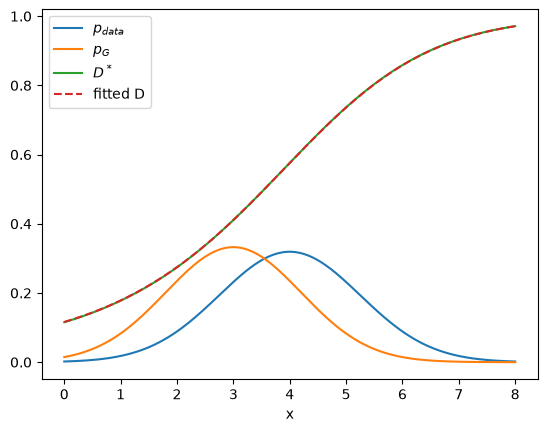

In [5]:
grid = np.linspace(0, 8, 200)
d_star = norm.pdf(grid, DATA_MEAN, DATA_STD) / (norm.pdf(grid, DATA_MEAN, DATA_STD) + norm.pdf(grid, 3, 1.2))

samples = torch.cat([DATA_MEAN + DATA_STD * torch.randn(100_000), 3 + 1.2 * torch.randn(100_000)])
is_real = torch.cat([torch.ones(100_000), torch.zeros(100_000)])
fitted_D = TorchDiscriminator()
optimizer = torch.optim.Adam(fitted_D.parameters(), lr=0.05)
for _ in range(1000):
    optimizer.zero_grad()
    bce(fitted_D(samples), is_real).backward()
    optimizer.step()

with torch.no_grad():
    d_fitted = torch.sigmoid(fitted_D(torch.from_numpy(grid))).numpy()
print("same result (tolerance 0.02):", np.allclose(d_star, d_fitted, atol=0.02))

plt.plot(grid, norm.pdf(grid, DATA_MEAN, DATA_STD), label="$p_{data}$")
plt.plot(grid, norm.pdf(grid, 3, 1.2), label="$p_G$")
plt.plot(grid, d_star, label="$D^*$")
plt.plot(grid, d_fitted, linestyle="--", label="fitted D")
plt.xlabel("x")
plt.legend()
plt.show()

When $p_G = p_{\text{data}}$, $D^* = \tfrac12$ everywhere and $V = \log\tfrac12 + \log\tfrac12 = -\log 4$.

In [6]:
x = rng.normal(DATA_MEAN, DATA_STD, 10)
d_star_equal = norm.pdf(x, DATA_MEAN, DATA_STD) / (2 * norm.pdf(x, DATA_MEAN, DATA_STD))
print("same result:", np.allclose(d_star_equal, 0.5) and np.isclose(2 * np.log(0.5), -np.log(4)))

same result: True


## 4. Training in turns

The generator is $G(z) = a z + b$. Each round: `D_STEPS` steps of gradient descent on $L_D$, then one step for $G$ on the
non-saturating loss $L_G = -\log D(G(z))$. By the chain rule, $\dfrac{\partial L_G}{\partial G(z)} = -(1 - D)\,\dfrac{\partial s}{\partial x}$, where $s$ is $D$'s score.
The NumPy optimizer copies the shape of `torch.optim.SGD`.

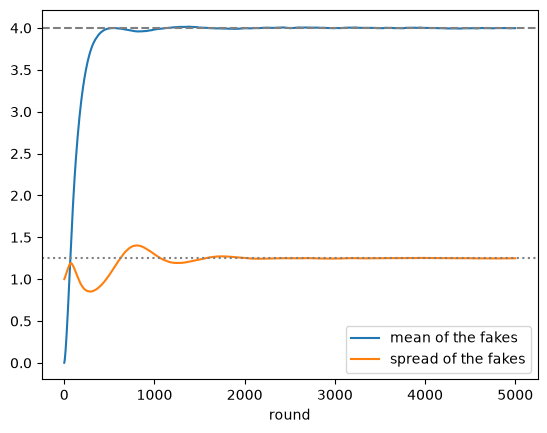

In [7]:
class Generator:
    """NumPy generator G(z) = weight * z + bias."""

    def __init__(self, weight: float, bias: float):
        self.weight, self.bias = np.array([weight]), np.array([bias])

    def forward(self, z: np.ndarray) -> np.ndarray:
        return self.weight * z + self.bias

    def backward(self, z: np.ndarray, grad_x: np.ndarray) -> list[np.ndarray]:
        """Gradients for weight and bias, given dL/dx for each generated x."""
        return [np.array([grad_x @ z]), np.array([grad_x.sum()])]


class SGD:
    """NumPy version of torch.optim.SGD; step() takes the gradients because NumPy arrays have no .grad."""

    def __init__(self, params: list[np.ndarray], lr: float):
        self.params, self.lr = params, lr

    def step(self, grads: list[np.ndarray]) -> None:
        for param, grad in zip(self.params, grads):
            param -= self.lr * grad


G, D = Generator(1.0, 0.0), Discriminator([0.0, 0.0], 0.0)
optimizer_G, optimizer_D = SGD([G.weight, G.bias], LEARNING_RATE_G), SGD([D.weight, D.bias], LEARNING_RATE_D)
history = []
for _ in range(ROUNDS):
    for _ in range(D_STEPS):
        x_real, x_fake = rng.normal(DATA_MEAN, DATA_STD, BATCH), G.forward(rng.normal(size=BATCH))
        optimizer_D.step(D.backward(x_real, x_fake))
    z = rng.normal(size=BATCH)
    x_fake = G.forward(z)
    grad_x = -(1 - sigmoid(D.forward(x_fake))) * D.input_gradient(x_fake) / BATCH
    optimizer_G.step(G.backward(z, grad_x))
    history.append((G.bias[0], abs(G.weight[0])))

plt.plot(np.array(history), label=["mean of the fakes", "spread of the fakes"])
plt.axhline(DATA_MEAN, color="gray", linestyle="--")
plt.axhline(DATA_STD, color="gray", linestyle=":")
plt.xlabel("round")
plt.legend()
plt.show()

The same loop in PyTorch, with two optimizers. $G(z) = az + b$ is exactly `nn.Linear(1, 1)`.
In the $D$ step the fakes are `detach()`ed so no gradient flows into $G$; the $G$ step labels its fakes as real (1), which is $-\log D(G(z))$.

In [8]:
torch_G, torch_D = nn.Linear(1, 1), TorchDiscriminator()
with torch.no_grad():
    torch_G.weight.fill_(1.0)
    torch_G.bias.fill_(0.0)
    torch_D.linear.weight.zero_()
    torch_D.linear.bias.zero_()
optimizer_G = torch.optim.SGD(torch_G.parameters(), lr=LEARNING_RATE_G)
optimizer_D = torch.optim.SGD(torch_D.parameters(), lr=LEARNING_RATE_D)
real_label, fake_label = torch.ones(BATCH), torch.zeros(BATCH)
for _ in range(ROUNDS):
    for _ in range(D_STEPS):
        x_real = DATA_MEAN + DATA_STD * torch.randn(BATCH)
        x_fake = torch_G(torch.randn(BATCH, 1)).squeeze(1).detach()
        optimizer_D.zero_grad()
        (bce(torch_D(x_real), real_label) + bce(torch_D(x_fake), fake_label)).backward()
        optimizer_D.step()
    optimizer_G.zero_grad()
    bce(torch_D(torch_G(torch.randn(BATCH, 1)).squeeze(1)), real_label).backward()
    optimizer_G.step()

Both versions move the fakes' mean and spread toward the data's. Training is noisy, so we compare with a tolerance of 0.1.

In [9]:
generated = G.forward(rng.normal(size=100_000))
with torch.no_grad():
    torch_generated = torch_G(torch.randn(100_000, 1)).numpy()
for name, sample in [("NumPy", generated), ("PyTorch", torch_generated)]:
    print(f"{name}: generated mean {sample.mean():.2f}, std {sample.std():.2f} | close to the data (tolerance 0.1):",
          np.isclose(sample.mean(), DATA_MEAN, atol=0.1) and np.isclose(sample.std(), DATA_STD, atol=0.1))

NumPy: generated mean 3.99, std 1.25 | close to the data (tolerance 0.1): True
PyTorch: generated mean 3.99, std 1.26 | close to the data (tolerance 0.1): True


## Exercises

1. In the PyTorch loop of section 4, replace $L_G$ by the saturating loss $\log(1 - D(G(z)))$, that is `-bce(torch_D(...), fake_label)`, and start the generator far away (bias $-5$). What changes?
2. Set `D_STEPS = 1`. Is training still as stable?
3. Remove the $x^2$ feature from `TorchDiscriminator`. Can the generator still learn the right spread? Why?